In [2]:
import numpy as np
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

We will load the latent features, and use the original 32-dimensional data to cluster. We will also perform UMAP again, but this is only for visualization.

In [3]:
# Load the data to analyse
features = pd.read_csv('MDSAE_latent_features.csv', index_col=None) # Load from csv
n_dims = 32
feature_array = features[['latent_mean_{}'.format(i) for i in range(n_dims)]]

## K-means clustering
To perform K-means clustering we will need to set a number of clusters. Best practice is to test multiple cluster numbers, and then find the optimum. There's no straightforward answer to what the optimum number is, here we'll apply the  [elbow method](https://www.geeksforgeeks.org/machine-learning/elbow-method-for-optimal-value-of-k-in-kmeans/) to sum of squared errors of the cluster point distance to the cluster centres. Other options are metrics like the [silhouette score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).

Other methods for clustering exist too, like HDBSCAN, Gausian Mixture Models, and many others, which you can find [here](https://scikit-learn.org/stable/modules/clustering.html). [This interesting paper](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0125785) also looked at different clustering methods for acoustic data specific.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

n_cluster_max = 20 # The max number of clusters we're gonna test
n_cluster_tests = np.arange(2, n_cluster_max)
random_state = 10 # Use the same initial state for repeatability

SSE = np.full((len(n_cluster_tests)), np.nan)

# Now we'll loop through and find the silhouette score for each cluster number
for i,cluster_size in enumerate(n_cluster_tests):
    kmeans = KMeans(n_clusters=cluster_size, random_state=random_state)
    y_pred = kmeans.fit_predict(feature_array)
    SSE[i] = kmeans.inertia_

In [ ]:
plt.plot(n_cluster_tests,SSE)
plt.ylabel('SSE')
plt.xlabel('Number of clusters')

The optimal number seems to be around 4, so the optimum solution seems to be 4 clusters. Let's look at this in 2D UMAP space

In [23]:
optimum_cluster = 4
kmeans = KMeans(n_clusters=optimum_cluster, random_state=random_state)
y_pred = kmeans.fit_predict(feature_array)


C:\Users\grijseels\.conda\envs\audio_analysis\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


In [24]:
import umap
reducer = umap.UMAP()
umap_results = reducer.fit_transform(feature_array) # fit_transform fits the model and gives you the results

# Put everything in a dataframe
umap_results_df = pd.DataFrame(umap_results, columns=["UMAP1", "UMAP2"])
umap_results_df['cluster'] = y_pred


<Axes: xlabel='UMAP1', ylabel='UMAP2'>

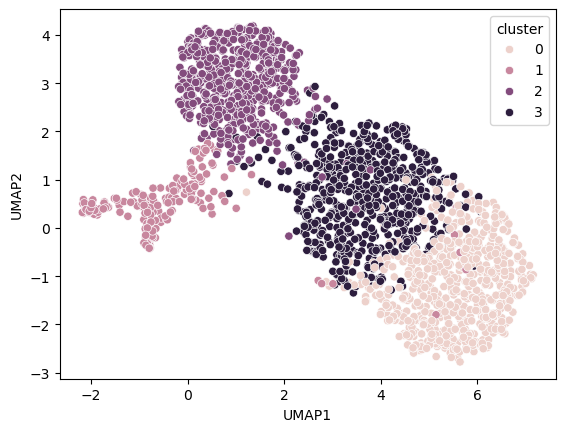

In [25]:
# Plot the results
sns.scatterplot(data=umap_results_df, x="UMAP1", y="UMAP2", hue="cluster")

## Classification
A common method of determining whether the vocalizations hold information about certain aspects, e.g. the individual who produced the sound, or the type of sound produced, is to try and train a machine learning model to predict it. For this we'll use a classifier. As with clustering algorithms, many are available, for some examples see [here](https://scikit-learn.org/stable/auto_examples/classification/plot_classifier_comparison.html). Here we'll use a [random forest classifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), which is a combination of decision trees (essentially a flowchart) to determine what is the best class based on the data input. This is a type of non-linear classifier (but also performs well on linear problems).

We want to train the classifier to predict the type of call from the latent features.

In [55]:
# Load the data to analyse
features = pd.read_csv('MDSAE_latent_features.csv', index_col=None) # Load from csv
n_dims = 32
feature_array = features[['latent_mean_{}'.format(i) for i in range(n_dims)]].values
call_type = features['call_type'].values

We will use cross-validation, basically meaning we'll train the model on a part of the data and test it on a held out chunk, but we do this several times, so each chunk of data gets to be in the training and test set. Because we don't have the same number of calls for each call type, we want to do a stratified K-folds (i.e. each chunk or fold contains the same relative number from each call type)

Note that we're using default settings for the models, you can do a lot of tweaking and training (e.g. [grid searching](https://scikit-learn.org/stable/modules/grid_search.html) for optimal parameter settings). 

In [65]:
from sklearn.model_selection import StratifiedKFold
n_folds = 10 # the number of folds we'll use
skf = StratifiedKFold(n_splits=n_folds)


In [92]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, balanced_accuracy_score
# Arrays to save out the accuracy scores
mean_cm = np.full([n_folds, len(np.unique(call_type)), len(np.unique(call_type))], np.nan)
accuracy = np.full((n_folds, 1), np.nan)

# Now we can loop through and train the models
for i, (train_index, test_index) in enumerate(skf.split(feature_array, call_type)):
    print(f"Fold {i}")
    # Divide the data in train and test data
    X_train = feature_array[train_index,:]
    X_test  = feature_array[test_index,:]
    y_train = call_type[train_index]
    y_test  = call_type[test_index]

    # Create and train a random forest classifier
    rf = RandomForestClassifier(random_state=random_state)
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)
    
    # Test the accuracy of the trained model
    cm = confusion_matrix(y_test, y_pred)
    cmn = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] # Get it as probabilities
    mean_cm[i, :,:] = cmn
    accuracy[i] = balanced_accuracy_score(y_test, y_pred, adjusted=False)

Fold 0
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
Fold 6
Fold 7
Fold 8
Fold 9


We saved out two accuracy scores: the accuracy score, which calculates the percentage of calls that were correctedly predicted, and the confusion matrix, which shows the percentage of each call type and prediction pair. Let's first look at the latter

Text(50.722222222222214, 0.5, 'True label')

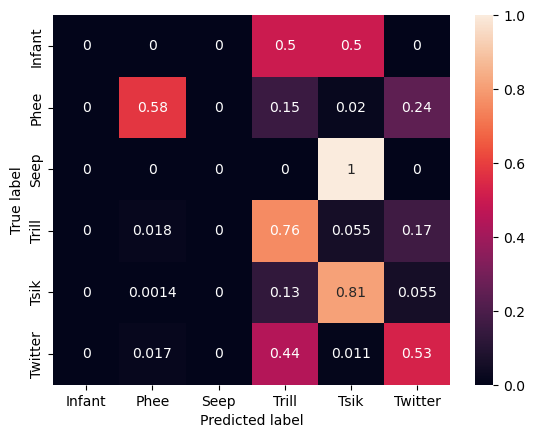

In [93]:
categories = np.unique(call_type)
sns.heatmap(np.nanmean(mean_cm, 0), annot=True,  xticklabels=categories,yticklabels=categories)
plt.xlabel('Predicted label')
plt.ylabel('True label')


It seems like the phees, trills, tsiks and twitters are generally classified correctly. The infant and seep calls are never classified correctly. This is not dissimilar to what the classification also showed: four distint classes of calls. Let's look at our overall accuracy: 

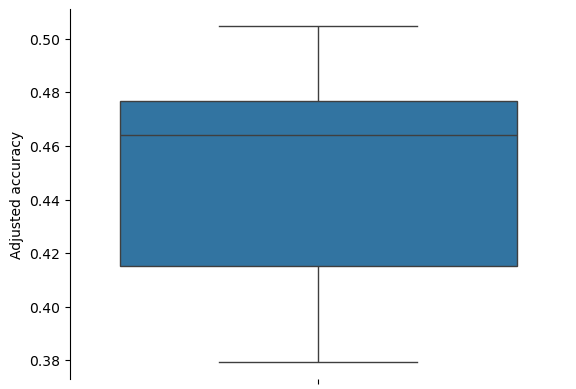

In [95]:
sns.boxplot(y=np.squeeze(accuracy))
plt.ylabel('Adjusted accuracy')
sns.despine(bottom = True, left = False)

On average, just over 46% of calls are correctly predicted, which is not a very good score. This may speak to the graduality of marmoset calls. However, with tweaking of features used and parameters of the models, this could most likely be improved. 